# Napa vintage prediction: 2000–2016, with a 2000 vs 2016 comparison

Adapted from `project3.ipynb`. The **main model learns all available vintage years from 2000 through 2016**. The final analysis compares its predictions for actual 2000 (worst) and 2016 (best) wines. A separate optional binary classifier directly distinguishes 2000 from 2016.

Uses the original model families: metadata-only logistic regression and TF-IDF descriptions + metadata logistic regression. Wine quality scores (`points`) are not the target.

In [1]:
import pandas as pd

wine_df = pd.read_csv("winemag-data-130k-v2.csv", index_col=0)
wine_df["title"].head(10)

0                    Nicosia 2013 Vulkà Bianco  (Etna)
1        Quinta dos Avidagos 2011 Avidagos Red (Douro)
2        Rainstorm 2013 Pinot Gris (Willamette Valley)
3    St. Julian 2013 Reserve Late Harvest Riesling ...
4    Sweet Cheeks 2012 Vintner's Reserve Wild Child...
5    Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...
6     Terre di Giurfo 2013 Belsito Frappato (Vittoria)
7                Trimbach 2012 Gewurztraminer (Alsace)
8    Heinz Eifel 2013 Shine Gewürztraminer (Rheinhe...
9    Jean-Baptiste Adam 2012 Les Natures Pinot Gris...
Name: title, dtype: object

In [2]:
wine_df["wine vintage"] = (
    wine_df["title"]
    .str.extract(r"\b((?:19|20)\d{2})\b", expand=False)
    .astype("Int64")
)

wine_df[["title", "wine vintage"]].head(10)

,title,wine vintage
0,Nicosia 2013 Vulkà Bianco (Etna),2013
1,Quinta dos Avidagos 2011 Avidagos Red (Douro),2011
2,Rainstorm 2013 Pinot Gris (Willamette Valley),2013
3,St. Julian 2013 Reserve Late Harvest Riesling ...,2013
4,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,2012
5,Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...,2011
6,Terre di Giurfo 2013 Belsito Frappato (Vittoria),2013
7,Trimbach 2012 Gewurztraminer (Alsace),2012
8,Heinz Eifel 2013 Shine Gewürztraminer (Rheinhe...,2013
9,Jean-Baptiste Adam 2012 Les Natures Pinot Gris...,2012


In [43]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

selected_vintages = list(range(2000, 2017))
napa = (wine_df.loc[
    wine_df["region_2"].eq("Napa") &
    wine_df["wine vintage"].isin(selected_vintages),
    ["title", "description", "wine vintage", "variety", "region_1"]
].dropna(subset=["title", "wine vintage"])
 .drop_duplicates(subset="title").copy())

napa["description"] = napa["description"].fillna("").astype(str)
for col in ["variety", "region_1"]:
    napa[col] = napa[col].fillna("Unknown").astype(str)
napa["wine vintage"] = napa["wine vintage"].astype(int)

# Group on exactly the same normalization used in the leakage check.
groups = napa["description"].str.strip().str.lower()
# Missing/blank descriptions are not useful for text learning.
napa = napa.loc[groups.ne("")].copy()
groups = groups.loc[napa.index]

X = napa[["variety", "region_1", "description"]].copy()
y = napa["wine vintage"].copy()
print("Counts per year:")
print(y.value_counts().sort_index().to_string())
print("Total wines:", len(y))

# Find a grouped split that includes both focal years in train and test.
splitter = GroupShuffleSplit(n_splits=100, test_size=0.2, random_state=42)
split_found = False
for train_pos, test_pos in splitter.split(X, y, groups):
    train_years = set(y.iloc[train_pos])
    test_years = set(y.iloc[test_pos])
    if {2000, 2016}.issubset(train_years) and {2000, 2016}.issubset(test_years):
        split_found = True
        break
if not split_found:
    raise ValueError("Could not find a split containing both 2000 and 2016 in training and testing. Inspect year counts.")

X_train, X_test = X.iloc[train_pos].copy(), X.iloc[test_pos].copy()
y_train, y_test = y.iloc[train_pos].copy(), y.iloc[test_pos].copy()
assert set(groups.iloc[train_pos]).isdisjoint(set(groups.iloc[test_pos]))
print("\nTrain/test counts for 2000 and 2016:")
print(pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()}).reindex([2000, 2016]).fillna(0).astype(int))
print(f"Training: {len(X_train)} | Testing: {len(X_test)}")

Counts per year:
wine vintage
2000     52
2001     24
2002      5
2003     22
2004    169
2005    344
2006    355
2007    476
2008    505
2009    683
2010    659
2011    469
2012    893
2013    834
2014    446
2015    131
2016     68
Total wines: 6135

Train/test counts for 2000 and 2016:
              Train  Test
wine vintage             
2000             43     9
2016             56    12
Training: 4907 | Testing: 1228


## Train the original model families across 2000–2016

In [44]:
def clean_vintage_description(text):
    return re.sub(r"\b(?:18|19|20|21)\d{2}\b", " ", str(text)).lower()

metadata_cols = ["variety", "region_1"]
baseline_model = Pipeline([
    ("categories", OneHotEncoder(handle_unknown="ignore")),
    ("classifier", LogisticRegression(max_iter=1500, random_state=42))
])
baseline_model.fit(X_train[metadata_cols], y_train)

combined_vintage_pipeline = Pipeline([
    ("features", ColumnTransformer([
        ("text", TfidfVectorizer(
            preprocessor=clean_vintage_description,
            lowercase=False, min_df=2, max_features=5000
        ), "description"),
        ("metadata", OneHotEncoder(handle_unknown="ignore"), metadata_cols)
    ])),
    ("classifier", LogisticRegression(max_iter=1500, random_state=42))
])

# Rare classes can make five-fold stratification impossible.
# Group identical descriptions during cross-validation
train_groups = (
    X_train["description"]
    .str.strip()
    .str.lower()
)

min_train_count = int(y_train.value_counts().min())

if min_train_count >= 2:
    folds = min(5, min_train_count)

    cv = StratifiedGroupKFold(
        n_splits=folds,
        shuffle=True,
        random_state=42
    )

    combined_search = GridSearchCV(
        combined_vintage_pipeline,
        {"classifier__C": [0.03, 0.1, 0.3, 1.0]},
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        error_score="raise"
    )

    combined_search.fit(
        X_train,
        y_train,
        groups=train_groups
    )

    description_vintage_model = combined_search.best_estimator_

    print(
        "Selected C:",
        combined_search.best_params_["classifier__C"]
    )

else:
    description_vintage_model = combined_vintage_pipeline
    description_vintage_model.fit(X_train, y_train)

    print("Skipped CV because a vintage has only one training example.")

baseline_predictions = baseline_model.predict(X_test[metadata_cols])
description_vintage_predictions = description_vintage_model.predict(X_test)
print(pd.DataFrame([
    {"Model": "Metadata baseline",
     "Accuracy": accuracy_score(y_test, baseline_predictions),
     "Macro F1": f1_score(y_test, baseline_predictions, average="macro", zero_division=0)},
    {"Model": "Descriptions + metadata",
     "Accuracy": accuracy_score(y_test, description_vintage_predictions),
     "Macro F1": f1_score(y_test, description_vintage_predictions, average="macro", zero_division=0)}
]).round(3).to_string(index=False))

Selected C: 1.0
                  Model  Accuracy  Macro F1
      Metadata baseline     0.148     0.054
Descriptions + metadata     0.336     0.190


## Compare how the full 2000–2016 model predicts 2000 versus 2016

For each actual year, **exact-year recall** is the proportion correctly predicted as that year. Also compare absolute year error and the most common wrong predictions.

         Test wines  Correct  Exact-year recall  Precision  Mean absolute year error
Vintage                                                                             
2000              9        0                0.0        0.0                    11.111
2016             12        0                0.0        0.0                     2.000

Most common predictions for actual 2000 and 2016:

Actual 2000:
Predicted
2011    3
2010    2
2015    1
2014    1
2012    1
2006    1

Actual 2016:
Predicted
2014    10
2015     1
2013     1


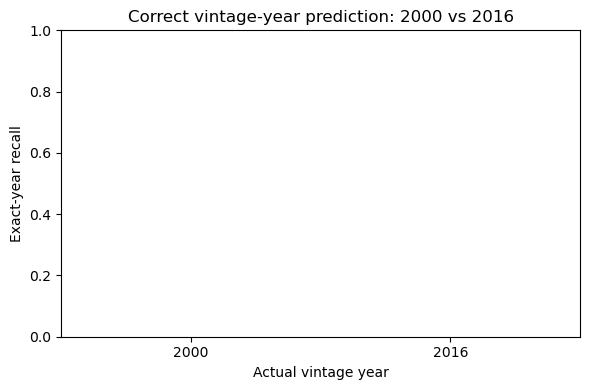

In [45]:
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": description_vintage_predictions
}, index=y_test.index)
results["Absolute year error"] = (results["Actual"] - results["Predicted"]).abs()
rows = []
for year in [2000, 2016]:
    subset = results.loc[results["Actual"].eq(year)]
    predicted_as_year = results["Predicted"].eq(year)
    true_year = results["Actual"].eq(year)
    precision_denom = predicted_as_year.sum()
    rows.append({
        "Vintage": year,
        "Test wines": len(subset),
        "Correct": int((subset["Predicted"] == year).sum()),
        "Exact-year recall": (subset["Predicted"] == year).mean() if len(subset) else np.nan,
        "Precision": ((predicted_as_year & true_year).sum() / precision_denom
                      if precision_denom else 0.0),
        "Mean absolute year error": subset["Absolute year error"].mean()
    })
comparison_2000_2016 = pd.DataFrame(rows).set_index("Vintage")
print(comparison_2000_2016.round(3).to_string())
print("\nMost common predictions for actual 2000 and 2016:")
for year in [2000, 2016]:
    print(f"\nActual {year}:")
    print(results.loc[results.Actual.eq(year), "Predicted"].value_counts().head(10).to_string())

ax = comparison_2000_2016["Exact-year recall"].plot(
    kind="bar", figsize=(6, 4), rot=0, ylim=(0, 1),
    title="Correct vintage-year prediction: 2000 vs 2016"
)
ax.set_ylabel("Exact-year recall")
ax.set_xlabel("Actual vintage year")
plt.tight_layout()
plt.show()

## Optional: direct binary classification of 2000 versus 2016

This is a **different question** from the full 17-year model: among wines known to come from either 2000 or 2016, can the classifier tell which one? We use the same held-out split to avoid training/test leakage.

              precision    recall  f1-score   support

        2000       0.78      0.78      0.78         9
        2016       0.83      0.83      0.83        12

    accuracy                           0.81        21
   macro avg       0.81      0.81      0.81        21
weighted avg       0.81      0.81      0.81        21



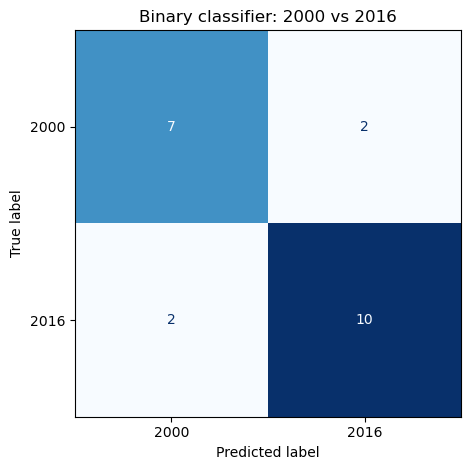

In [46]:
binary_train = y_train.isin([2000, 2016])
binary_test = y_test.isin([2000, 2016])
X_train_binary, y_train_binary = X_train.loc[binary_train], y_train.loc[binary_train]
X_test_binary, y_test_binary = X_test.loc[binary_test], y_test.loc[binary_test]
if y_train_binary.nunique() < 2 or y_test_binary.nunique() < 2:
    print("Not enough examples of both years for a binary comparison.")
else:
    binary_model = Pipeline([
        ("features", ColumnTransformer([
            ("text", TfidfVectorizer(
                preprocessor=clean_vintage_description,
                lowercase=False, min_df=1, max_features=5000
            ), "description"),
            ("metadata", OneHotEncoder(handle_unknown="ignore"), metadata_cols)
        ])),
        ("classifier", LogisticRegression(
    max_iter=1500,
    random_state=42
))
    ])
    binary_model.fit(X_train_binary, y_train_binary)
    binary_predictions = binary_model.predict(X_test_binary)
    print(classification_report(y_test_binary, binary_predictions,
                                labels=[2000, 2016], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test_binary, binary_predictions, labels=[2000, 2016],
        cmap="Blues", colorbar=False
    )
    plt.title("Binary classifier: 2000 vs 2016")
    plt.tight_layout()
    plt.show()

with balancing:

              precision    recall  f1-score   support

        2000       0.80      0.89      0.84         9
        2016       0.91      0.83      0.87        12

    accuracy                           0.86        21
   macro avg       0.85      0.86      0.86        21
weighted avg       0.86      0.86      0.86        21



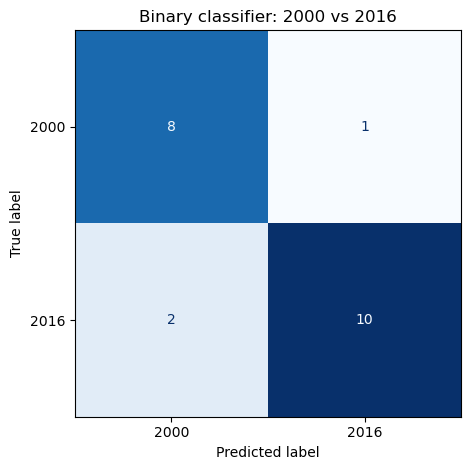

In [47]:
binary_train = y_train.isin([2000, 2016])
binary_test = y_test.isin([2000, 2016])
X_train_binary, y_train_binary = X_train.loc[binary_train], y_train.loc[binary_train]
X_test_binary, y_test_binary = X_test.loc[binary_test], y_test.loc[binary_test]
if y_train_binary.nunique() < 2 or y_test_binary.nunique() < 2:
    print("Not enough examples of both years for a binary comparison.")
else:
    binary_model = Pipeline([
        ("features", ColumnTransformer([
            ("text", TfidfVectorizer(
                preprocessor=clean_vintage_description,
                lowercase=False, min_df=1, max_features=5000
            ), "description"),
            ("metadata", OneHotEncoder(handle_unknown="ignore"), metadata_cols)
        ])),
        ("classifier", LogisticRegression(
    max_iter=1500,
    class_weight = "balanced",
    random_state=42
))
    ])
    binary_model.fit(X_train_binary, y_train_binary)
    binary_predictions = binary_model.predict(X_test_binary)
    print(classification_report(y_test_binary, binary_predictions,
                                labels=[2000, 2016], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test_binary, binary_predictions, labels=[2000, 2016],
        cmap="Blues", colorbar=False
    )
    plt.title("Binary classifier: 2000 vs 2016")
    plt.tight_layout()
    plt.show()

In [48]:
from sklearn.metrics import classification_report, balanced_accuracy_score

binary_predictions = binary_model.predict(X_test_binary)

print(classification_report(
    y_test_binary,
    binary_predictions,
    zero_division=0
))

print("Balanced accuracy:",
      balanced_accuracy_score(y_test_binary, binary_predictions))

print("Macro F1:",
      f1_score(y_test_binary, binary_predictions, average="macro"))

              precision    recall  f1-score   support

        2000       0.80      0.89      0.84         9
        2016       0.91      0.83      0.87        12

    accuracy                           0.86        21
   macro avg       0.85      0.86      0.86        21
weighted avg       0.86      0.86      0.86        21

Balanced accuracy: 0.8611111111111112
Macro F1: 0.8558352402745995


### Interpretation caution

Different sample sizes, review wording, reviewer practices, and class imbalance can affect performance. A difference between 2000 and 2016 does **not** by itself prove vintage quality causes the difference. In the full model, report the test counts alongside exact-year recall.

In [7]:
# Eyeball error analysis: Full model (2000–2016)

full_errors = X_test.copy()

full_errors["actual_vintage"] = y_test
full_errors["predicted_vintage"] = description_vintage_predictions
full_errors["year_error"] = abs(
    full_errors["actual_vintage"] - full_errors["predicted_vintage"]
)

# Only incorrectly predicted wines
full_errors = full_errors[
    full_errors["actual_vintage"] != full_errors["predicted_vintage"]
]

# Sort by largest prediction error
full_errors = full_errors.sort_values("year_error", ascending=False)

display(full_errors[
    ["actual_vintage", "predicted_vintage",
     "year_error", "variety", "region_1", "description"]
].head(20))

full_errors.to_csv("napa_full_model_eyeball_errors.csv", index=False)

,actual_vintage,predicted_vintage,year_error,variety,region_1,description
16845,2000,2015,15,Sauvignon Blanc,Napa Valley,"Hay, cabbage and pickles in the nose? That's n..."
30872,2000,2014,14,Sauvignon Blanc,Napa Valley,"A touch of the veggies, particularly asparagus..."
64615,2000,2012,12,Cabernet Sauvignon,Napa Valley,"Quite spicy in the nose, with hints of pretty ..."
32513,2000,2011,11,Shiraz,Napa Valley,The wine starts of with intriguing bacon and e...
24349,2000,2011,11,Sauvignon Blanc,Oakville,"Aromas of glue, bacon fat and earth make for a..."
38063,2000,2011,11,Cabernet Sauvignon,Napa Valley,"Always reliable, and often a value, this vinta..."
22757,2000,2010,10,Fumé Blanc,Napa Valley,"Hardly run of the mill, this offering is just ..."
73683,2000,2010,10,Merlot,Napa County,"A success despite a certain leanness, a young ..."
43209,2004,2012,8,Cabernet Sauvignon,St. Helena,"Bright and forward in red and black cherry, pl..."
44094,2001,2009,8,Sauvignon Blanc,Napa Valley,"Smells simple, with vague notes of citrus frui..."


In [9]:
# Eyeball error analysis: Binary model (2000 vs. 2016)

binary_errors = X_test_binary.copy()

binary_errors["actual_vintage"] = y_test_binary
binary_errors["predicted_vintage"] = binary_predictions

# Only incorrectly predicted wines
binary_errors = binary_errors[
    binary_errors["actual_vintage"] != binary_errors["predicted_vintage"]
]

display(binary_errors[
    ["actual_vintage", "predicted_vintage",
     "variety", "region_1", "description"]
].head(20))

binary_errors.to_csv("napa_binary_model_eyeball_errors.csv", index=False)

,actual_vintage,predicted_vintage,variety,region_1,description
11571,2016,2000,Viognier,Napa Valley,"A 100% varietal wine, this is dry and in balan..."
16845,2000,2016,Sauvignon Blanc,Napa Valley,"Hay, cabbage and pickles in the nose? That's n..."
30872,2000,2016,Sauvignon Blanc,Napa Valley,"A touch of the veggies, particularly asparagus..."
62326,2016,2000,Albariño,Napa Valley,This strengthens the argument that there's a p...


### 2000 - 2016
comparing 2011 & 2016 w/ full model

In [49]:
# Compare 2011 and 2016 using the full model

full_comparison = X_test.copy()

full_comparison["actual_vintage"] = y_test
full_comparison["predicted_vintage"] = description_vintage_predictions

full_comparison = full_comparison[
    full_comparison["actual_vintage"].isin([2011, 2016])
].copy()

full_comparison["correct"] = (
    full_comparison["actual_vintage"] ==
    full_comparison["predicted_vintage"]
)

full_comparison["year_error"] = abs(
    full_comparison["actual_vintage"] -
    full_comparison["predicted_vintage"]
)

# Accuracy and average year error for each vintage
full_summary = full_comparison.groupby("actual_vintage").agg(
    total=("correct", "size"),
    correct=("correct", "sum"),
    accuracy=("correct", "mean"),
    mean_year_error=("year_error", "mean")
)

display(full_summary)

# Eyeball errors
display(
    full_comparison[~full_comparison["correct"]][
        ["actual_vintage", "predicted_vintage",
         "year_error", "variety", "region_1", "description"]
    ].sort_values("year_error", ascending=False).head(20)
)

full_comparison.to_csv("napa_full_2011_2016.csv", index=False)

,total,correct,accuracy,mean_year_error
actual_vintage,,,,
2011,104,7,0.067308,1.346154
2016,12,0,0.000000,2.000000


,actual_vintage,predicted_vintage,year_error,variety,region_1,description
56989,2011,2007,4,Cabernet Sauvignon,Napa Valley,"A huge, powerful Cabernet, this is stuffed wit..."
96882,2011,2014,3,Cabernet Sauvignon,Napa Valley,"With small percentages of Merlot and Malbec, t..."
90239,2011,2008,3,Cabernet Sauvignon,Napa Valley,"A rustic, everyday Cabernet, with enough black..."
36965,2011,2014,3,Zinfandel,Napa Valley,Red dusty berry cobbler marks the entry to thi...
17704,2011,2008,3,Red Blend,Napa Valley,The fabulous 2012 vintage has resulted in a fi...
121714,2011,2014,3,Rosé,Napa Valley,"With a dark color and full body, this isn't ve..."
48445,2016,2013,3,Sauvignon Blanc,Napa Valley,"Steely like a wet stone, this refreshing, ligh..."
86666,2011,2008,3,Chardonnay,Napa Valley,"A good, if fairly standard wine, showing all t..."
52485,2011,2014,3,Sauvignon Blanc-Semillon,Napa Valley,"Low in alcohol by California standards, but of..."
50881,2011,2013,2,Petite Sirah,Calistoga,A broad and expansive wine eager in youthful t...


Binary Classifier

              precision    recall  f1-score   support

        2011       0.94      0.99      0.97       104
        2016       0.86      0.50      0.63        12

    accuracy                           0.94       116
   macro avg       0.90      0.75      0.80       116
weighted avg       0.94      0.94      0.93       116



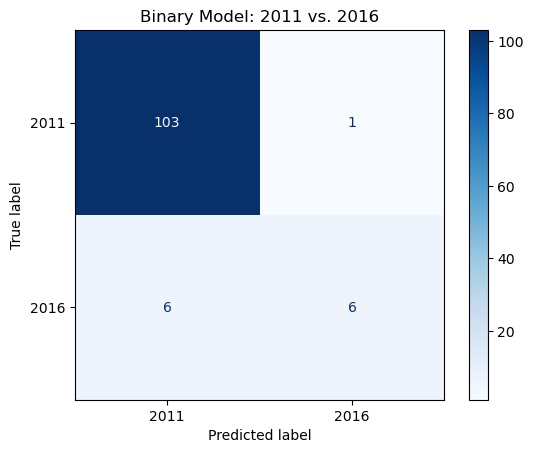

In [50]:
# Train binary classifier for 2011 vs. 2016

binary_train = y_train.isin([2011, 2016])
binary_test = y_test.isin([2011, 2016])

X_train_binary = X_train.loc[binary_train]
y_train_binary = y_train.loc[binary_train]

X_test_binary = X_test.loc[binary_test]
y_test_binary = y_test.loc[binary_test]

binary_model = Pipeline([
    ("features", ColumnTransformer([
        ("text", TfidfVectorizer(
            preprocessor=clean_vintage_description,
            lowercase=False,
            min_df=1,
            max_features=5000
        ), "description"),
        ("metadata", OneHotEncoder(handle_unknown="ignore"),
         metadata_cols)
    ])),
    ("classifier", LogisticRegression(
        max_iter=1500,
        random_state=42
    ))
])

binary_model.fit(X_train_binary, y_train_binary)

binary_predictions = binary_model.predict(X_test_binary)

print(classification_report(
    y_test_binary,
    binary_predictions,
    labels=[2011, 2016],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    binary_predictions,
    labels=[2011, 2016],
    cmap="Blues"
)

plt.title("Binary Model: 2011 vs. 2016")
plt.show()

              precision    recall  f1-score   support

        2011       0.98      0.89      0.93       104
        2016       0.48      0.83      0.61        12

    accuracy                           0.89       116
   macro avg       0.73      0.86      0.77       116
weighted avg       0.93      0.89      0.90       116



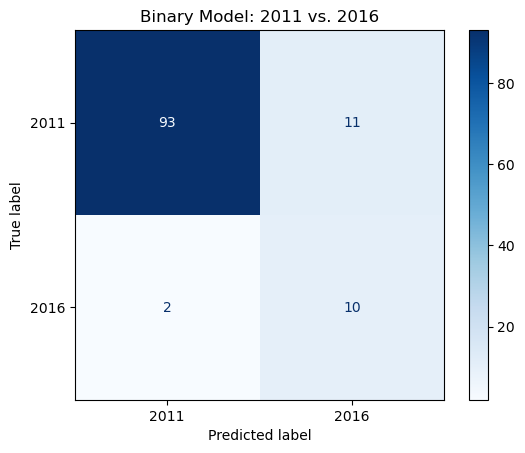

In [51]:
# Train binary classifier for 2011 vs. 2016

binary_train = y_train.isin([2011, 2016])
binary_test = y_test.isin([2011, 2016])

X_train_binary = X_train.loc[binary_train]
y_train_binary = y_train.loc[binary_train]

X_test_binary = X_test.loc[binary_test]
y_test_binary = y_test.loc[binary_test]

binary_model = Pipeline([
    ("features", ColumnTransformer([
        ("text", TfidfVectorizer(
            preprocessor=clean_vintage_description,
            lowercase=False,
            min_df=1,
            max_features=5000
        ), "description"),
        ("metadata", OneHotEncoder(handle_unknown="ignore"),
         metadata_cols)
    ])),
    ("classifier", LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=42
    ))
])

binary_model.fit(X_train_binary, y_train_binary)

binary_predictions = binary_model.predict(X_test_binary)

print(classification_report(
    y_test_binary,
    binary_predictions,
    labels=[2011, 2016],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    binary_predictions,
    labels=[2011, 2016],
    cmap="Blues"
)

plt.title("Binary Model: 2011 vs. 2016")
plt.show()

In [52]:
binary_comparison = X_test_binary.copy()

binary_comparison["actual_vintage"] = y_test_binary
binary_comparison["predicted_vintage"] = binary_predictions

binary_comparison["correct"] = (
    binary_comparison["actual_vintage"] ==
    binary_comparison["predicted_vintage"]
)

binary_summary = binary_comparison.groupby("actual_vintage").agg(
    total=("correct", "size"),
    correct=("correct", "sum"),
    accuracy=("correct", "mean")
)

display(binary_summary)

# Show incorrectly predicted wines
binary_errors = binary_comparison[
    ~binary_comparison["correct"]
]

display(binary_errors[
    ["actual_vintage", "predicted_vintage",
     "variety", "region_1", "description"]
].head(20))

binary_errors.to_csv("napa_binary_2011_2016.csv", index=False)

,total,correct,accuracy
actual_vintage,,,
2011,104,93,0.894231
2016,12,10,0.833333


,actual_vintage,predicted_vintage,variety,region_1,description
4464,2011,2016,Sauvignon Blanc,Rutherford,"Nice and crisp in acidity, with a brisk, clean..."
11571,2016,2011,Viognier,Napa Valley,"A 100% varietal wine, this is dry and in balan..."
53228,2011,2016,Sauvignon Blanc,Rutherford,"Flavors of green hay, tart juniper berry and g..."
56273,2011,2016,Sauvignon Blanc,St. Helena,"This is dry, full bodied and spicy. It's all a..."
57328,2011,2016,Sauvignon Blanc,Napa Valley,"Tasting a little on the sweet side, this is ri..."
62326,2016,2011,Albariño,Napa Valley,This strengthens the argument that there's a p...
65375,2011,2016,Sauvignon Blanc,Rutherford,"While there's no oak here, there's a heft and ..."
66709,2011,2016,Sauvignon Blanc,Napa Valley,A touch of honey brings a sense of sweetness t...
74115,2011,2016,Sauvignon Blanc,Napa Valley,"This is dry, acidic and a little underripe, wi..."
76456,2011,2016,Rosé,Napa Valley,To call this rosé deep is an understatement. I...


,Vintage,Full Model,Binary Model
0,2011,0.067308,0.894231
1,2016,0.000000,0.833333


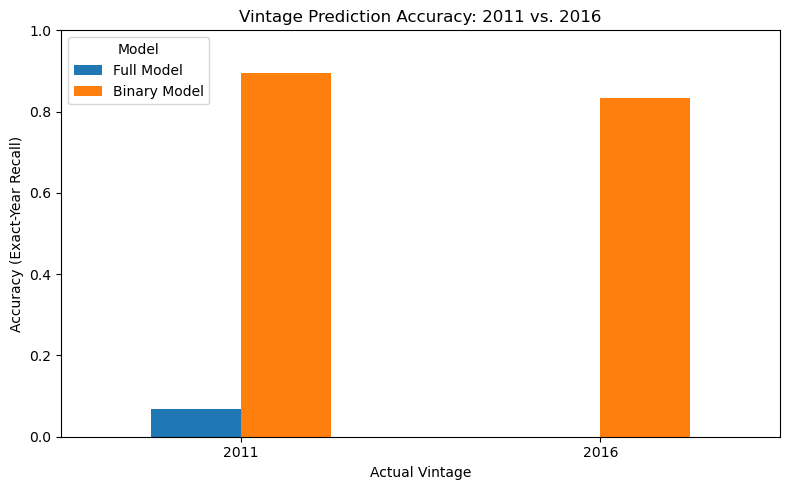

In [53]:
comparison = pd.DataFrame({
    "Vintage": [2011, 2016],
    "Full Model": [
        full_summary.loc[2011, "accuracy"],
        full_summary.loc[2016, "accuracy"]
    ],
    "Binary Model": [
        binary_summary.loc[2011, "accuracy"],
        binary_summary.loc[2016, "accuracy"]
    ]
})

display(comparison)

comparison.set_index("Vintage").plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Vintage Prediction Accuracy: 2011 vs. 2016")
plt.ylabel("Accuracy (Exact-Year Recall)")
plt.xlabel("Actual Vintage")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

sonoma test

In [54]:
from sklearn.metrics import balanced_accuracy_score, confusion_matrix

# Check how Sonoma is coded in the source dataset.
print("Sonoma-related region_2 values:")
print(wine_df.loc[
    wine_df["region_2"].fillna("").str.contains("sonoma", case=False),
    "region_2"
].value_counts().to_string())

# region_2 == "Sonoma" is the Sonoma counterpart to the original Napa filter.
sonoma = wine_df.loc[
    wine_df["region_2"].fillna("").eq("Sonoma") &
    wine_df["wine vintage"].isin(selected_vintages),
    ["title", "description", "wine vintage", "variety", "region_1"]
].dropna(subset=["title", "wine vintage"]).drop_duplicates(subset="title").copy()

sonoma["description"] = sonoma["description"].fillna("").astype(str)
for col in ["variety", "region_1"]:
    sonoma[col] = sonoma[col].fillna("Unknown").astype(str)
sonoma["wine vintage"] = sonoma["wine vintage"].astype(int)

# Match Napa preprocessing, and remove overlapping wine titles and reviews.
sonoma = sonoma.loc[sonoma["description"].str.strip().ne("")].copy()
napa_titles = set(napa["title"].astype(str).str.strip().str.lower())
napa_reviews = set(napa["description"].str.strip().str.lower())
sonoma = sonoma.loc[
    ~sonoma["title"].astype(str).str.strip().str.lower().isin(napa_titles) &
    ~sonoma["description"].str.strip().str.lower().isin(napa_reviews)
].copy()

X_sonoma = sonoma[["variety", "region_1", "description"]].copy()
y_sonoma = sonoma["wine vintage"].copy()
print("\nSonoma sample counts:")
print(y_sonoma.value_counts().sort_index().to_string())
if len(y_sonoma) == 0:
    raise ValueError("No eligible Sonoma wines found. Inspect region_2 values and the filtering conditions.")

# Models were fitted on Napa only; predict Sonoma without fitting again.
sonoma_full_pred = description_vintage_model.predict(X_sonoma)
sonoma_metadata_pred = baseline_model.predict(X_sonoma[metadata_cols])

def metric_row(name, actual, predicted):
    return {
        "Model": name,
        "N": len(actual),
        "Accuracy": accuracy_score(actual, predicted),
        "Macro F1": f1_score(actual, predicted, average="macro", zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(actual, predicted)
    }

print("\nNapa holdout vs. Sonoma external test (full 17-year model):")
display(pd.DataFrame([
    metric_row("Napa: metadata baseline", y_test, baseline_predictions),
    metric_row("Sonoma: metadata baseline", y_sonoma, sonoma_metadata_pred),
    metric_row("Napa: descriptions + metadata", y_test, description_vintage_predictions),
    metric_row("Sonoma: descriptions + metadata", y_sonoma, sonoma_full_pred)
]).round(3))

print("\nSonoma full-model performance by year:")
print(classification_report(y_sonoma, sonoma_full_pred,
                            labels=selected_vintages, zero_division=0))

sonoma_full_review = sonoma.copy()
sonoma_full_review["predicted_vintage"] = sonoma_full_pred
sonoma_full_review["year_error"] = (y_sonoma - sonoma_full_pred).abs()
sonoma_full_review["correct"] = y_sonoma.eq(sonoma_full_pred)
print("\nSonoma full-model errors (largest year errors first):")
display(sonoma_full_review.loc[~sonoma_full_review["correct"]]
        .sort_values("year_error", ascending=False)
        [["wine vintage", "predicted_vintage", "year_error", "variety", "region_1", "description"]].head(20))
sonoma_full_review.to_csv("sonoma_full_model_predictions.csv", index=False)

Sonoma-related region_2 values:
region_2
Sonoma         9028
Napa-Sonoma    1169

Sonoma sample counts:
wine vintage
2000      45
2001      36
2002      14
2003      21
2004      90
2005     277
2006     456
2007     544
2008     478
2009     694
2010     790
2011     647
2012    1184
2013    1203
2014    1127
2015     405
2016     102

Napa holdout vs. Sonoma external test (full 17-year model):


,Model,N,Accuracy,Macro F1,Balanced accuracy
0,Napa: metadata baseline,1228,0.148,0.054,0.068
1,Sonoma: metadata baseline,8113,0.150,0.033,0.062
2,Napa: descriptions + metadata,1228,0.336,0.190,0.195
3,Sonoma: descriptions + metadata,8113,0.266,0.144,0.149



Sonoma full-model performance by year:
              precision    recall  f1-score   support

        2000       0.00      0.00      0.00        45
        2001       0.00      0.00      0.00        36
        2002       0.00      0.00      0.00        14
        2003       0.00      0.00      0.00        21
        2004       0.62      0.06      0.10        90
        2005       0.27      0.10      0.15       277
        2006       0.27      0.13      0.17       456
        2007       0.25      0.11      0.15       544
        2008       0.20      0.18      0.19       478
        2009       0.20      0.30      0.24       694
        2010       0.25      0.36      0.29       790
        2011       0.19      0.16      0.17       647
        2012       0.31      0.34      0.32      1184
        2013       0.29      0.65      0.40      1203
        2014       0.32      0.12      0.17      1127
        2015       0.24      0.03      0.05       405
        2016       0.17      0.01      0.

,wine vintage,predicted_vintage,year_error,variety,region_1,description
65344,2000,2014,14,Chardonnay,Russian River Valley,Textbook RRV Chard reveals green apple and int...
81377,2000,2014,14,Gamay,Sonoma,"This awkward wine is youthful and sharp, with ..."
74535,2000,2013,13,Sauvignon Blanc,Sonoma County,"From the get-go it's a big, full grapefruit-dr..."
86568,2000,2013,13,Zinfandel,Sonoma County,"The Sonoma County blend is warm and spicy, mix..."
96029,2000,2013,13,Pinot Noir,Russian River Valley,Clearly a step in quality above the winery's r...
127778,2000,2013,13,Fumé Blanc,Dry Creek Valley,Wheat grass and hot peppers make for an intrig...
46828,2000,2013,13,Zinfandel,Russian River Valley,"Smells superripe and overly extracted, with ja..."
125781,2000,2013,13,Chardonnay,Russian River Valley,"From Green Valley, the coolest part of the app..."
65325,2000,2013,13,Chardonnay,Russian River Valley,"This is a soft, creamy Chardonnay that's remin..."
124337,2000,2013,13,Chardonnay,Russian River Valley,Interesting and compelling. Somehow the wine c...


Sonoma 2000/2016 counts:
wine vintage
2011    647
2016    102

Napa holdout vs. Sonoma external test (binary model):


,Model,N,Accuracy,Macro F1,Balanced accuracy
0,Napa binary holdout,116,0.888,0.770,0.864
1,Sonoma binary external,749,0.885,0.758,0.760



Sonoma binary per-year results:
              precision    recall  f1-score   support

        2011       0.93      0.93      0.93       647
        2016       0.58      0.59      0.58       102

    accuracy                           0.89       749
   macro avg       0.76      0.76      0.76       749
weighted avg       0.89      0.89      0.89       749



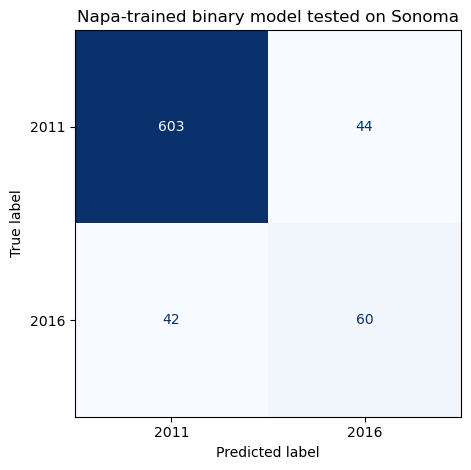


Sonoma binary eyeball errors:


,wine vintage,predicted_vintage,variety,region_1,description
34,2011,2016,Sauvignon Blanc,Sonoma Valley,"This shows a tart, green gooseberry flavor tha..."
503,2011,2016,Sauvignon Blanc,Russian River Valley,Sauvignon Blanc has been a consistent performe...
2428,2011,2016,Rosé,Sonoma Mountain,"A big, heavy rosé, this has an orange-pink col..."
4408,2016,2011,Viognier,Russian River Valley,This wine is lovely in aromatics of honeysuckl...
4622,2016,2011,Tempranillo,Sonoma County,"And now for something completely different, th..."
6000,2016,2011,Pinot Gris,Russian River Valley,"Muted florals make way for a creamy, lush and ..."
6628,2011,2016,Sauvignon Blanc,Alexander Valley,"New Zealand-like in style, with brisk acidity ..."
6642,2011,2016,Sauvignon Blanc,Russian River Valley,"A refreshing wine, tart in acidity, with savor..."
11416,2016,2011,Syrah,Knights Valley,"Perfumed and floral, crisp and modulated in ac..."
13070,2016,2011,Pinot Noir,Russian River Valley,"This bright, light and acid-driven wine is jui..."


In [55]:
target_years = [2011, 2016]
if set(binary_model.classes_) != set(target_years):
    raise ValueError(f"binary_model was trained for {binary_model.classes_.tolist()}, not [2000, 2016]. Rerun the Napa 2011/2016 binary training cell.")

sonoma_binary_mask = y_sonoma.isin(target_years)
X_sonoma_binary = X_sonoma.loc[sonoma_binary_mask]
y_sonoma_binary = y_sonoma.loc[sonoma_binary_mask]

print("Sonoma 2000/2016 counts:")
print(y_sonoma_binary.value_counts().reindex(target_years, fill_value=0).to_string())
if not set(target_years).issubset(set(y_sonoma_binary)):
    print("WARNING: Both years are not represented in Sonoma. Per-class comparisons are incomplete.")

if len(y_sonoma_binary):
    sonoma_binary_pred = binary_model.predict(X_sonoma_binary)
    print("\nNapa holdout vs. Sonoma external test (binary model):")
    display(pd.DataFrame([
        metric_row("Napa binary holdout", y_test_binary, binary_predictions),
        metric_row("Sonoma binary external", y_sonoma_binary, sonoma_binary_pred)
    ]).round(3))
    print("\nSonoma binary per-year results:")
    print(classification_report(y_sonoma_binary, sonoma_binary_pred,
                                labels=target_years, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_sonoma_binary, sonoma_binary_pred, labels=target_years,
        cmap="Blues", colorbar=False
    )
    plt.title("Napa-trained binary model tested on Sonoma")
    plt.tight_layout()
    plt.show()

    sonoma_binary_review = sonoma.loc[sonoma_binary_mask].copy()
    sonoma_binary_review["predicted_vintage"] = sonoma_binary_pred
    sonoma_binary_review["correct"] = y_sonoma_binary.eq(sonoma_binary_pred)
    print("\nSonoma binary eyeball errors:")
    display(sonoma_binary_review.loc[~sonoma_binary_review["correct"],
        ["wine vintage", "predicted_vintage", "variety", "region_1", "description"]].head(20))
    sonoma_binary_review.to_csv("sonoma_binary_model_predictions.csv", index=False)
else:
    print("No Sonoma wines available for binary evaluation.")

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Select Napa training examples for 2011 and 2016
train_mask = y_train.isin([2011, 2016])

X_napa = X_train.loc[train_mask].copy()
y_napa = y_train.loc[train_mask].copy()

# Select Sonoma examples for the same two years
sonoma = wine_df[
    (wine_df["region_2"] == "Sonoma") &
    (wine_df["wine vintage"].isin([2011, 2016]))
].copy()

sonoma = sonoma.dropna(subset=["description", "wine vintage"])

# Keep necessary columns
features = ["description", "variety", "region_1"]

X_sonoma = sonoma[features].copy()
y_sonoma = sonoma["wine vintage"].astype(int)

# Fill missing values
for col in features:
    X_napa[col] = X_napa[col].fillna("")
    X_sonoma[col] = X_sonoma[col].fillna("")

# Remove duplicate descriptions from the Sonoma test set
sonoma_text = X_sonoma["description"].str.strip().str.lower()
X_sonoma = X_sonoma.loc[~sonoma_text.duplicated()].copy()
y_sonoma = y_sonoma.loc[X_sonoma.index]

# Prevent identical descriptions from crossing regions
napa_text = set(
    X_napa["description"].str.strip().str.lower()
)

overlap = X_sonoma["description"].str.strip().str.lower().isin(napa_text)
X_sonoma = X_sonoma.loc[~overlap].copy()
y_sonoma = y_sonoma.loc[X_sonoma.index]

print("Napa training samples:")
print(y_napa.value_counts().sort_index())

print("\nSonoma testing samples:")
print(y_sonoma.value_counts().sort_index())

Napa training samples:
wine vintage
2011    365
2016     56
Name: count, dtype: int64

Sonoma testing samples:
wine vintage
2011    647
2016    102
Name: count, dtype: int64


# 1) Model Performance

In [57]:
feature_sets = {
    "Descriptions only": [],
    "Descriptions + Variety": ["variety"],
    "Descriptions + Variety + Region": ["variety", "region_1"]
}

ablation_results = []
ablation_predictions = {}

for name, metadata in feature_sets.items():

    transformers = [
        ("text", TfidfVectorizer(
            preprocessor=clean_vintage_description,
            lowercase=False,
            min_df=2,
            max_features=5000
        ), "description")
    ]

    if metadata:
        transformers.append(
            ("metadata", OneHotEncoder(handle_unknown="ignore"), metadata)
        )

    model = Pipeline([
        ("features", ColumnTransformer(transformers)),
        ("classifier", LogisticRegression(
            max_iter=1500,
            class_weight="balanced",
            random_state=42
        ))
    ])

    model.fit(X_napa, y_napa)

    predictions = model.predict(X_sonoma)
    ablation_predictions[name] = predictions

    ablation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_sonoma, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_sonoma, predictions),
        "Macro F1": f1_score(
            y_sonoma, predictions, average="macro"
        ),
        "2011 Recall": np.mean(
            predictions[y_sonoma.to_numpy() == 2011] == 2011
        ),
        "2016 Recall": np.mean(
            predictions[y_sonoma.to_numpy() == 2016] == 2016
        )
    })

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(3))

,Model,Accuracy,Balanced Accuracy,Macro F1,2011 Recall,2016 Recall
0,Descriptions only,0.948,0.920,0.896,0.958,0.882
1,Descriptions + Variety,0.889,0.795,0.778,0.924,0.667
2,Descriptions + Variety + Region,0.893,0.777,0.775,0.937,0.618


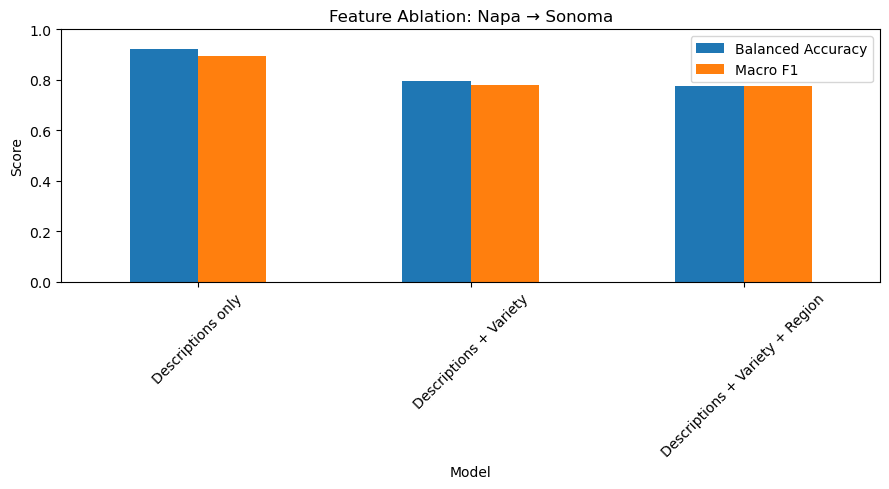

In [58]:
ablation_df.set_index("Model")[
    ["Balanced Accuracy", "Macro F1"]
].plot(kind="bar", figsize=(9, 5), rot=45)

plt.title("Feature Ablation: Napa → Sonoma")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

2) Model Balancing

In [59]:
balance_results = []
balance_predictions = {}

for name, weight in {
    "Unbalanced": None,
    "Balanced": "balanced"
}.items():

    model = Pipeline([
        ("features", ColumnTransformer([
            ("text", TfidfVectorizer(
                preprocessor=clean_vintage_description,
                lowercase=False,
                min_df=2,
                max_features=5000
            ), "description"),

            ("metadata", OneHotEncoder(
                handle_unknown="ignore"
            ), ["variety", "region_1"])
        ])),

        ("classifier", LogisticRegression(
            max_iter=1500,
            class_weight=weight,
            random_state=42
        ))
    ])

    model.fit(X_napa, y_napa)

    predictions = model.predict(X_sonoma)
    balance_predictions[name] = predictions

    balance_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_sonoma, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_sonoma, predictions),
        "Macro F1": f1_score(
            y_sonoma, predictions, average="macro"
        ),
        "2011 Recall": np.mean(
            predictions[y_sonoma.to_numpy() == 2011] == 2011
        ),
        "2016 Recall": np.mean(
            predictions[y_sonoma.to_numpy() == 2016] == 2016
        )
    })

balance_df = pd.DataFrame(balance_results)

display(balance_df.round(3))

,Model,Accuracy,Balanced Accuracy,Macro F1,2011 Recall,2016 Recall
0,Unbalanced,0.925,0.725,0.790,1.000,0.451
1,Balanced,0.893,0.777,0.775,0.937,0.618


# 3) Errors

In [60]:
# Predictions from the full-feature ablation model
predictions = ablation_predictions[
    "Descriptions + Variety + Region"
]

error_df = X_sonoma.copy()

error_df["actual_vintage"] = y_sonoma
error_df["predicted_vintage"] = predictions

error_df["correct"] = (
    error_df["actual_vintage"] ==
    error_df["predicted_vintage"]
)

# Incorrect predictions
errors = error_df[~error_df["correct"]].copy()

print("Total errors:", len(errors))

display(errors[
    ["actual_vintage", "predicted_vintage",
     "variety", "region_1", "description"]
].head(20))

Total errors: 80


,actual_vintage,predicted_vintage,variety,region_1,description
34,2011,2016,Sauvignon Blanc,Sonoma Valley,"This shows a tart, green gooseberry flavor tha..."
503,2011,2016,Sauvignon Blanc,Russian River Valley,Sauvignon Blanc has been a consistent performe...
2428,2011,2016,Rosé,Sonoma Mountain,"A big, heavy rosé, this has an orange-pink col..."
4408,2016,2011,Viognier,Russian River Valley,This wine is lovely in aromatics of honeysuckl...
4622,2016,2011,Tempranillo,Sonoma County,"And now for something completely different, th..."
6000,2016,2011,Pinot Gris,Russian River Valley,"Muted florals make way for a creamy, lush and ..."
6642,2011,2016,Sauvignon Blanc,Russian River Valley,"A refreshing wine, tart in acidity, with savor..."
11416,2016,2011,Syrah,Knights Valley,"Perfumed and floral, crisp and modulated in ac..."
13070,2016,2011,Pinot Noir,Russian River Valley,"This bright, light and acid-driven wine is jui..."
13258,2011,2016,Sauvignon Blanc,Dry Creek Valley,This crisp Sauvignon Blanc shows how well the ...


In [61]:
variety_errors = (
    error_df.groupby("variety")
    .agg(
        total=("correct", "size"),
        errors=("correct", lambda x: (~x).sum()),
        accuracy=("correct", "mean")
    )
    .sort_values("total", ascending=False)
)

# Only varieties with at least 10 wines
variety_errors = variety_errors[
    variety_errors["total"] >= 10
]

display(variety_errors)

,total,errors,accuracy
variety,,,
Pinot Noir,211,13,0.938389
Chardonnay,140,3,0.978571
Zinfandel,82,1,0.987805
Sauvignon Blanc,75,30,0.600000
Cabernet Sauvignon,58,0,1.000000
Syrah,25,3,0.880000
Rosé,21,8,0.619048
Merlot,21,0,1.000000
Red Blend,15,0,1.000000


In [62]:
vintage_errors = (
    error_df.groupby("actual_vintage")
    .agg(
        total=("correct", "size"),
        errors=("correct", lambda x: (~x).sum()),
        accuracy=("correct", "mean")
    )
)

display(vintage_errors)

,total,errors,accuracy
actual_vintage,,,
2011,647,41,0.936631
2016,102,39,0.617647
